# Shot 60 Analysis

Decaying shock in fused silica near the temperature inversion on the principal Hugoniot.

Driver and Flyer are SS304.

Erik Davies<br>
Sarah T. Stewart<br>
July 26, 2024<br>
Updated May 13, 2025<br>



In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output


# Z Hugoniot fit
#qtz_liq_hug = 'KD09' # or `KD13` # pick which quartz Hugoniot equation
#qtz_liq_hug = 'NEW' # or `KD13` # pick which quartz Hugoniot equation
%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

#%run -i scripts/load_vapor_domes.py
#%run -i scripts/load_liquid_model.py
#%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-calcs.py



## Target Configuration

```{figure} ./shot60/shot60-target.png
---
width: 750px
name: shot60-target-info
---
```

## MAVIS Impact Velocity system

MAVIS inter-coil distance = 50.00 mm<br>
Time of Flight =  8.141023954999998 +/- 0.005656854249486605 us<br>
Velocity =  6.141733555432095 +/- 0.004924228116409747 km/s<p>

Anaysis file: MAVIS_Velocity_Analysis_v2.py


```{figure} ./shot60/Shot_60_MAVISRecord.png
---
width: 500px
name: shot60-mavis
---
```


## Initial Impedance Match

Using github-impactswiki: impedance-match-app-mc/impedance_match_app.ipynb<p>

Steel304-l2 is SS304 refit by sts. Fused-qtz-low is fit Us=2-10 km/s.

Impact velocity 6.14 (km/s). Hugoniot for reshock and release.

Steel304-l2 → Steel304-l2

 Steel304-l2 P = 221.27 (GPa), up = 3.07 (km/s), US = 0.0 (km/s), E = 4.72 (MJ/kg), ρ = 11.84 (g/cm3)


 Steel304-l2 P = 221.27 (GPa), up = 3.07 (km/s), US = 9.16 (km/s), E = 4.72 (MJ/kg), ρ = 11.84 (g/cm3)

Steel304-l2 → Fused-qtz-low
 
 Steel304-l2 P = 85.3 (GPa), up = 4.57 (km/s), US = 0.0 (km/s), E = 1.23 (MJ/kg), ρ = 10.18 (g/cm3)

 
 Fused-qtz-low P = 85.3 (GPa), up = 4.57 (km/s), US = 8.46 (km/s), E = 10.46 (MJ/kg), ρ = 4.8 (g/cm3)

IM Tool v1.3.0


```{figure} ./shot60/Shot60-impact-solution.png
---
width: 500px
name: shot60-IM-flip
---
```

Impact velocity 6.14 (km/s). Mie-Grueneisen model for reshock and release.

Steel304-l2 → Steel304-l2

 Steel304-l2 P = 221.27 (GPa), up = 3.07 (km/s), US = 0.0 (km/s), E = 4.72 (MJ/kg), ρ = 11.84 (g/cm3)

 Steel304-l2 P = 221.27 (GPa), up = 3.07 (km/s), US = 9.16 (km/s), E = 4.72 (MJ/kg), ρ = 11.84 (g/cm3)

Steel304-l2 → Fused-qtz-low

 Steel304-l2 P = 86.68 (GPa), up = 4.61 (km/s), US = 0.0 (km/s), E = 2.13 (MJ/kg), ρ = 9.76 (g/cm3)

 Fused-qtz-low P = 86.68 (GPa), up = 4.61 (km/s), US = 8.53 (km/s), E = 10.64 (MJ/kg), ρ = 4.8 (g/cm3)

IM Tool v1.3.0

```{figure} ./shot60/Shot60-impact-solution-gamma.png
---
width: 500px
name: shot60-IM-gamma
---
```

```{figure} ./shot60/IM-materials.png
---
width: 500px
name: shot60-IM-materials
---
```


## PDV Signals

3 channels; channel 1 no signal in sample. Does have breakout spall velocity.<br>
PDV fibers are pulled back from sample free surface.<br>
Pyro fiber is touching free surface. No breakout temperature.<p>

```{figure} ./shot60/Shot_60_ProbeMap_Pre-Shot.png
---
width: 750px
name: shot60-probe-map
---
```

Ch1: shock enters -0.345027 microsec<br>
shock exits? at 0.264973 microsec<br>
fiber destruction? at 1.13497 microsec<br>

Ch2: shock enters -0.325027 microsec<br>
shock exits at 0.274973 microsec<br>
fiber destruction? at 1.33497 microsec<br>

Ch3: shock enters -0.335027 microsec<br>
shock exits at 0.264972 microsec<br>
fiber destruction? at 1.10497 microsec<br>



## PDV Shock Velocities and Transit Thickness

Ch2 and Ch3 have nice reflecting shock front signals through the sample.<br>
Using Sandia SMASH-SIHREN2 v2.0 May 2023 to convert to shock front velocities.<br>




66


Text(0, 0.5, 'Shock Velocity (m/s)')

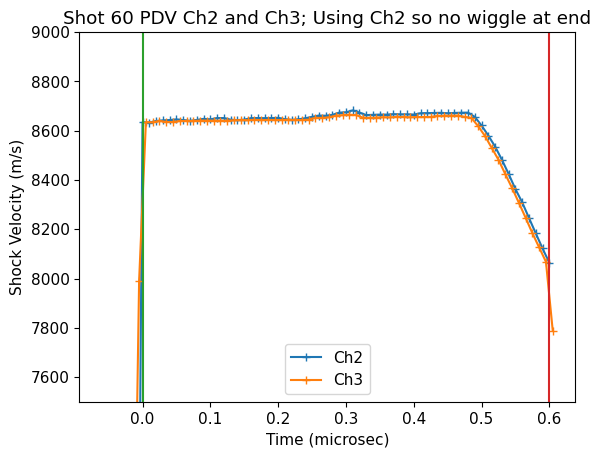

In [2]:

# Load SIHREN2 results - not corrected for offset or index

# offset 3769 m/s
# n = 1.444
pdv2data = np.loadtxt('shot60/Shot60-PDV-ch2-wider.txt',skiprows=30)
pdv2data[:,0]-=pdv2data[0,0]
pdv2data[:,0]*=1.e6
pdv2data[:,0]-=.06

userr1 = ((pdv2data[:,1]+pdv2data[:,2])+3769)/1.444
userr2 = ((pdv2data[:,1]-pdv2data[:,2])+3769)/1.444
uss = (pdv2data[:,1] + 3769)/1.444
pdv2data[:,1]+=3769
pdv2data[:,1]/=1.444
#pdv2data[:,2]*=pdv2data[:,1]/100 # in m/s
#pdv2data[:,2]+=3769
#pdv2data[:,2]/=1.444
#userr1 = ((pdv2data[:,1]+pdv2data[:,2])+3769)/1.444
#userr2 = ((pdv2data[:,1]-pdv2data[:,2])+3769)/1.444


# offset 4495 m/s
# n = 1.444
pdv3data = np.loadtxt('shot60/Shot60-PDV-ch3-wider.txt',skiprows=30,max_rows=66)
pdv3data[:,0]-=pdv3data[0,0]
pdv3data[:,0]*=1.e6
pdv3data[:,0]-=.045
pdv3data[:,1]+=4495
pdv3data[:,1]/=1.444
pdv3data[:,2]*=pdv3data[:,1]/100 # in m/s
print(len(pdv3data))

plt.plot(pdv2data[:,0],pdv2data[:,1],'-+',label='Ch2')
plt.plot(pdv3data[:,0],pdv3data[:,1],'-+',label='Ch3')
#plt.plot(pdv3data[:,0],pdv3data[:,1]+40,'-+',label='Ch3') # error is about 40 m/s
plt.plot([0.,0.],[0,10000])
plt.plot([0.6,0.6],[0,10000])
plt.legend()
plt.ylim(7500,9000)

plt.title('Shot 60 PDV Ch2 and Ch3; Using Ch2 so no wiggle at end')
plt.xlabel('Time (microsec)')
plt.ylabel('Shock Velocity (m/s)')

67 66


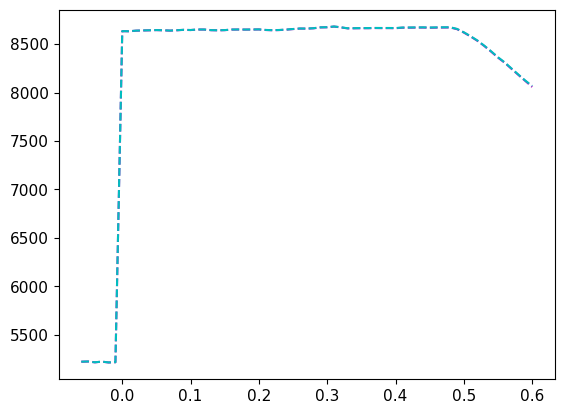

[ -0.42936288  -0.4432133   -0.4432133   -0.3601108   -0.41551247
  -0.45706371  -0.48476454  -0.48476454  -0.4432133   -0.4432133
  -0.45706371  -0.4432133   -0.49861496  -0.51246537  -0.49861496
  -0.52631579  -0.55401662  -0.55401662  -0.55401662  -0.56786704
  -0.55401662  -0.58171745  -0.58171745  -0.59556787  -0.6232687
  -0.65096953  -0.67867036  -0.66481994  -0.65096953  -0.69252078
  -0.73407202  -0.73407202  -0.73407202  -0.74792244  -0.8033241
  -0.81717452  -0.84487535  -0.92797784  -0.96952909  -1.05263158
  -1.17728532  -1.19113573  -1.28808864  -1.32963989  -1.38504155
  -1.52354571  -1.66204986  -1.66204986  -1.80055402  -1.93905817
  -1.93905817  -1.93905817  -2.21606648  -2.21606648  -2.49307479
  -2.35457064  -2.7700831   -2.90858726  -3.04709141  -3.04709141
  -3.46260388  -3.60110803  -3.46260388  -3.73961219  -3.73961219
  -3.60110803 -10.8033241 ]


In [3]:
#plt.errorbar(pdv2data[:,0],pdv2data[:,1],yerr=pdv2data[:,2],fmt='r+',label='Ch2')
#plt.errorbar(pdv3data[:,0],pdv3data[:,1],yerr=pdv3data[:,2],fmt='b+',label='Ch3')
print(len(pdv2data),len(pdv3data))
#plt.plot(pdv2data[:,0],uss,'k-')
plt.plot(pdv2data[:,0],userr2,'m--')
plt.plot(pdv2data[:,0],userr1,'c--')
#plt.ylim(4000,10000)
plt.show()
print(userr2-userr1)

In [4]:
## Initial shock velocity for impedance match solution
## 0.02-0.15 microsec
ind1=np.where((pdv3data[:,0]>0.02) & (pdv3data[:,0]<.15)  ) 
#ind1=np.where((pdv3data[:,0]>0.0) & (pdv3data[:,0]<.15)  ) 
print('PDV3 Us, Us_std (m/s)=')
print(np.mean(pdv3data[ind1,1]))
print(np.std(pdv3data[ind1,1]))
ind=np.where((pdv2data[:,0]>0.02) & (pdv2data[:,0]<.15)  ) 
print('PDV2 Us, Us_std (m/s)=')
print(np.mean(pdv2data[ind,1]))
print(np.std(pdv2data[ind,1]))
print('PDV2+PDV3 Us, Us_std (m/s)=')
print(np.mean([pdv2data[ind,1],pdv3data[ind1,1]]))
print(np.std([pdv2data[ind,1],pdv3data[ind1,1]]))
print('mean err=',np.mean([pdv2data[ind,2],pdv3data[ind1,2]]))
#print('mean err=',np.mean(pdv3data[ind1,2]))

Ussteady = np.mean([pdv2data[ind,1],pdv3data[ind1,1]])
Ussteady_err = np.mean([pdv2data[ind,2],pdv3data[ind1,2]])
print(Ussteady_err, np.mean([pdv2data[ind,2],pdv3data[ind1,2]]))
print(Ussteady_err/Ussteady)

PDV3 Us, Us_std (m/s)=
8639.858832303431
2.1535032865052357
PDV2 Us, Us_std (m/s)=
8645.07031749414
3.2362629652981023
PDV2+PDV3 Us, Us_std (m/s)=
8642.464574898786
3.787529757773608
mean err= 16.63664036863414
16.63664036863414 16.63664036863414
0.0019249879735641238


In [5]:
# Check integrated thickness with target thickness

xpos2 = [0.]
xpos3 = [0.]
ind = np.where(pdv2data[:,0]<0)
pdv2data[ind,1]=0
ind = np.where(pdv3data[:,0]<0)
pdv3data[ind,1]=0
ind = np.where(pdv3data[:,0]>.6)
if len(ind)>0:
    pdv3data[ind,1]=0
for i in range(1,len(pdv2data[:,0])):
    dt = pdv2data[i,0]-pdv2data[i-1,0]
    x2=pdv2data[i,1]*dt+xpos2[i-1]
    xpos2.append(x2)

for i in range(1,len(pdv3data[:,0])):
    dt = pdv3data[i,0]-pdv3data[i-1,0]
    x3=pdv3data[i,1]*dt+xpos3[i-1]
    xpos3.append(x3)

xpos2 = np.asarray(xpos2)/1.e3 # convert to mm
xpos3 = np.asarray(xpos3)/1.e3 # convert to mm
print('Shock travel distance (PDV2,PDV3) in mm = ',max(xpos2),max(xpos3))

print('Actual target thickness in center = 5.182+-0.0022 mm')

Shock travel distance (PDV2,PDV3) in mm =  5.161321342791553 5.1571546482501045
Actual target thickness in center = 5.182+-0.0022 mm


## Streak Camera Temperatures

See calibration and moving average notebook:

UCDavis_GasGunStreak_Direct_Cal_v2.ipynb

Using 10 ns moving average for temperature vs. time.


(2000.0, 6500.0)

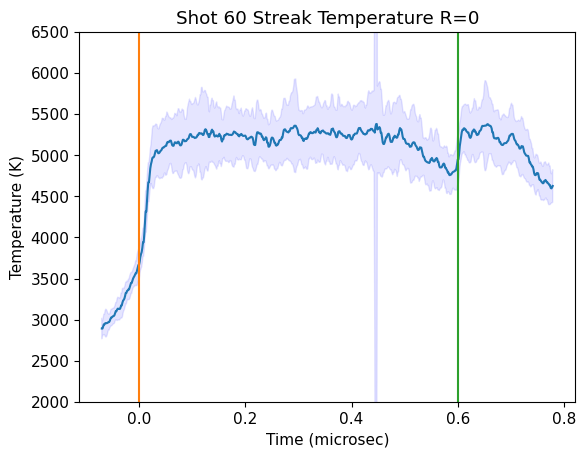

In [6]:
calstreak = np.loadtxt('shot60/shot60-temp-time-2.txt',skiprows=1,delimiter=',')
calstreak[:,0]-=calstreak[0,0]
dtstreak=-0.07
calstreak[:,0]+=dtstreak

plt.plot(calstreak[:,0],calstreak[:,1])
plt.fill_between(calstreak[:,0],calstreak[:,1]-calstreak[:,2],calstreak[:,1]+calstreak[:,2], color='blue', alpha = 0.1)
plt.plot([0.,0.],[0,10000])
plt.plot([0.6,0.6],[0,10000])
plt.title('Shot 60 Streak Temperature R=0')
plt.xlabel('Time (microsec)')
plt.ylabel('Temperature (K)')
plt.ylim(2000,6500)

## MC Impedance Match Solution

Using github-impactswiki: shot60/IM-MC-RL-Shot60.ipynb<p>

Using Steel304-l2 → Steel304-l2<br>
This solution is very close to the gamma release solution above but at a little higher shock velocity/pressure<p>

N= 1000<br>
Pressure mean, std (GPa) =  87.59627202805974 0.3358838977265427<br>
Density mean, std (kg/m3) =  4710.3980497641305 17.986888786740998<br>
Particle vel mean, std (km/s) =  4.598997692435084 0.007138691016889283<br>
Shock vel mean, std (km/s) =  8.64246 0.0012633333333333333<br>

```{figure} ./shot60/IM-MC-RL-Shot60-a.png
---
width: 500px
name: shot60-IM-MC-a
---
```

```{figure} ./shot60/IM-MC-RL-Shot60-b.png
---
width: 500px
name: shot60-IM-MC-b
---
```



## Convert PDV Us(time) to P(time) using new Hugoniot Fits for Fused Silica in the LIQUID region



4.211389841622867


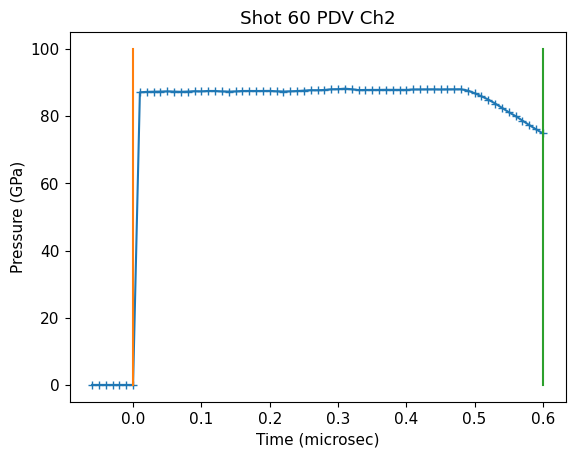

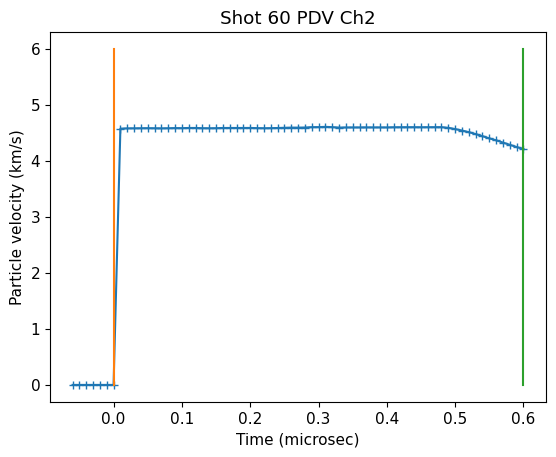

In [7]:
# convert Us to P using the liquid region fused silica fit
# latest version in scripts/define_eos.py
#fsresliq = [-0.01452743,  1.69390958,  1.15979627]
#fs_hug_liq.us = fsresliq[2]+fsresliq[1]*fs_hug_liq.up+fsresliq[0]*fs_hug_liq.up*fs_hug_liq.up # km/s
#fs_hug_liq.P = fs_hug_liq.rho_ref*fs_hug_liq.up*fs_hug_liq.us

#fitpres2 = np.interp(pdv2data[:,1]/1.e3,fs_hug_tra.us,fs_hug_tra.P)
#fitup2 = np.interp(pdv2data[:,1]/1.e3,fs_hug_tra.us,fs_hug_tra.up)

# orig
fitpres2 = np.interp(pdv2data[:,1]/1.e3,fs_hug_liq.us,fs_hug_liq.P)
fitup2 = np.interp(pdv2data[:,1]/1.e3,fs_hug_liq.us,fs_hug_liq.up)

# fix the very first point at time zero
#ind0 = np.where(np.abs(pdv2data[:,0])<1.e-10)[0]
#print(ind0)
#pdv2data[ind0,0]=0.0
#fitpres2[ind0]=fitpres2[ind0+1]
#print(pdv2data[ind0+1,0]) #.01 microsec
# zero out earlier time pressures
ind = np.where(pdv2data[:,0]<0)[0]
fitpres2[ind]=0
fitup2[ind]=0

#print(fitup2)
# print last particle velocity before breakout
print(fitup2[-1])
lastup2 = fitup2[-1]

plt.plot(pdv2data[:,0],fitpres2,'-+')
plt.plot([0.,0.],[0,100])
plt.plot([0.6,0.6],[0,100])
plt.title('Shot 60 PDV Ch2')
plt.xlabel('Time (microsec)')
plt.ylabel('Pressure (GPa)')
plt.show()


plt.plot(pdv2data[:,0],fitup2,'-+')
plt.plot([0.,0.],[0,6])
plt.plot([0.6,0.6],[0,6])
plt.title('Shot 60 PDV Ch2')
plt.xlabel('Time (microsec)')
plt.ylabel('Particle velocity (km/s)')
plt.show()

3.0


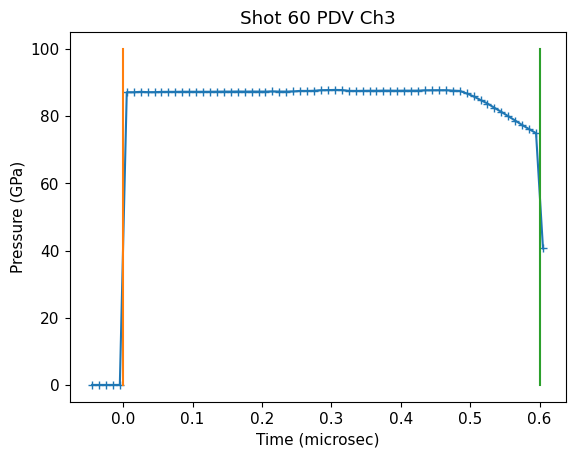

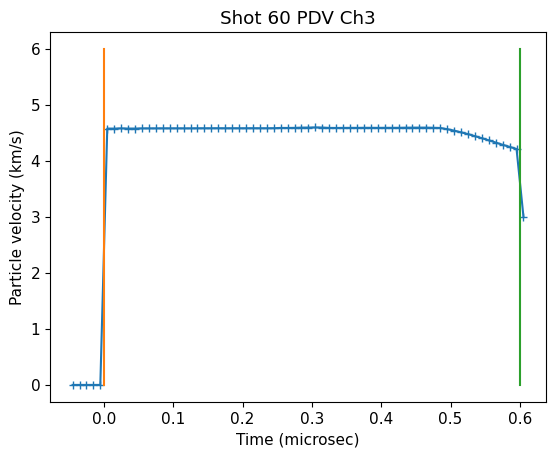

In [8]:
# convert Us to P using the liquid region fused silica fit
# latest version in scripts/define_eos.py
#fsresliq = [-0.01452743,  1.69390958,  1.15979627]
#fs_hug_liq.us = fsresliq[2]+fsresliq[1]*fs_hug_liq.up+fsresliq[0]*fs_hug_liq.up*fs_hug_liq.up # km/s
#fs_hug_liq.P = fs_hug_liq.rho_ref*fs_hug_liq.up*fs_hug_liq.us

#fitpres2 = np.interp(pdv2data[:,1]/1.e3,fs_hug_tra.us,fs_hug_tra.P)
#fitup2 = np.interp(pdv2data[:,1]/1.e3,fs_hug_tra.us,fs_hug_tra.up)

# orig
fitpres3 = np.interp(pdv3data[:,1]/1.e3,fs_hug_liq.us,fs_hug_liq.P)
fitup3 = np.interp(pdv3data[:,1]/1.e3,fs_hug_liq.us,fs_hug_liq.up)

# fix the very first point at time zero
#ind0 = np.where(np.abs(pdv2data[:,0])<1.e-10)[0]
#print(ind0)
#pdv2data[ind0,0]=0.0
#fitpres2[ind0]=fitpres2[ind0+1]
#print(pdv2data[ind0+1,0]) #.01 microsec
# zero out earlier time pressures
ind = np.where(pdv3data[:,0]<0)[0]
fitpres3[ind]=0
fitup3[ind]=0

#print(fitup2)
# print last particle velocity before breakout
print(fitup3[-1])
lastup3 = fitup3[-1]

plt.plot(pdv3data[:,0],fitpres3,'-+')
plt.plot([0.,0.],[0,100])
plt.plot([0.6,0.6],[0,100])
plt.title('Shot 60 PDV Ch3')
plt.xlabel('Time (microsec)')
plt.ylabel('Pressure (GPa)')
plt.show()


plt.plot(pdv3data[:,0],fitup3,'-+')
plt.plot([0.,0.],[0,6])
plt.plot([0.6,0.6],[0,6])
plt.title('Shot 60 PDV Ch3')
plt.xlabel('Time (microsec)')
plt.ylabel('Particle velocity (km/s)')
plt.show()

67


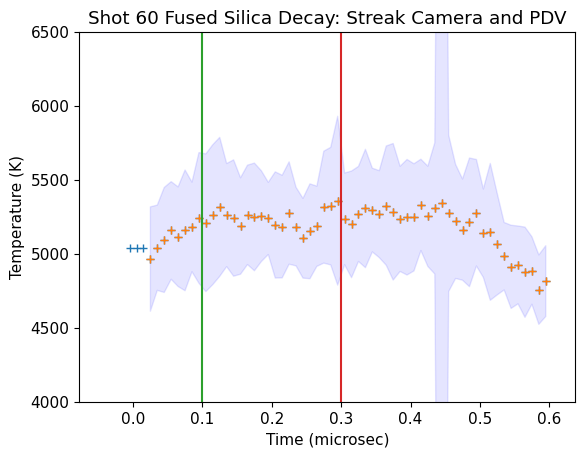

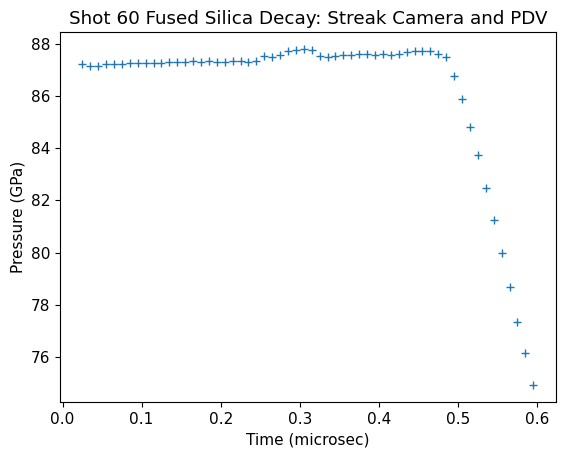

87.37549163492137 0.14386630934250794
5239.107596759999 61.87697604796183
5239.107596759999 362.8754952119999 87.37549163492137 0.14386630934250794 8642.464574898786 16.63664036863414


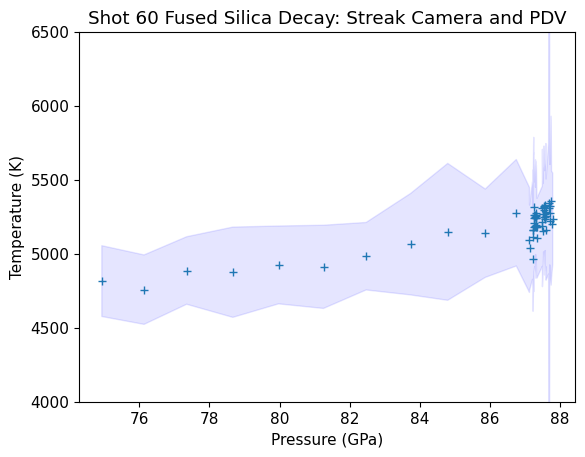

In [9]:
# interpolate P to match streak camera time array

print(len(pdv2data[:,0]))

if 0:
    # interpolate to the streak time resolution (> PDV resolution)
    s60time = calstreak[:,0]
    s60temp = calstreak[:,1]
    s60temperr = calstreak[:,2]
    s60pres = np.interp(s60time,pdv2data[:,0],fitpres2)
    s60us = np.interp(s60time,pdv2data[:,0],pdv2data[:,1])
    s60up = np.interp(s60time,pdv2data[:,0],fitup2)

if 0: # original streak
    # interpolate to the PDV resolution (< streak time resolution)
    s60time = pdv2data[:,0] #calstreak[:,0]
    s60temp =  np.interp(s60time,calstreak[:,0],calstreak[:,1])#calstreak[:,1]
    s60temperr = np.interp(s60time,calstreak[:,0],calstreak[:,2])
    s60pres = np.copy(fitpres2)
    s60us = np.copy(pdv2data[:,1])
    s60us = np.copy(pdv2data[:,1])
    s60up = np.copy(fitup2)

if 1: # use PDV3 with smaller uncertainties
    # interpolate to the PDV resolution (< streak time resolution)
    s60time = pdv3data[:,0] #calstreak[:,0]
    s60temp =  np.interp(s60time,calstreak[:,0],calstreak[:,1])#calstreak[:,1]
    s60temperr = np.interp(s60time,calstreak[:,0],calstreak[:,2])
    s60pres = np.copy(fitpres3)
    s60us = np.copy(pdv3data[:,1])
    s60us_err = np.copy(pdv3data[:,2])
    s60up = np.copy(fitup3)


ind = np.where(s60time<0)[0]
s60temp[ind]=0.
s60pres[ind]=0.
#s60temp[max(ind):max(ind)+9]=0.
#s60pres[max(ind):max(ind)+9]=0.
s60temp[max(ind):max(ind)+3]=s60temp[max(ind)+4]
s60pres[max(ind):max(ind)+3]=s60pres[max(ind)+4]
ind = np.where(s60time>.6)[0]
s60temp[ind]=0.
s60pres[ind]=0.

# remove the time period where the temperature is still rising in the streak camera
ind60 = np.where((s60time > 0.02) & (s60time <=0.6))[0]

plt.plot(s60time,s60temp,'+')
plt.plot(s60time[ind60],s60temp[ind60],'+')
plt.fill_between(s60time[ind60],s60temp[ind60]-s60temperr[ind60],s60temp[ind60]+s60temperr[ind60], color='blue', alpha = 0.1)
plt.ylim(4000,6500)
plt.plot([.1,.1],[4000,6500])
plt.plot([.3,.3],[4000,6500])
plt.xlabel('Time (microsec)')
plt.ylabel('Temperature (K)')
plt.title('Shot 60 Fused Silica Decay: Streak Camera and PDV')
plt.show()


plt.plot(s60time[ind60],s60pres[ind60],'+')
plt.ylabel('Pressure (GPa)')
plt.xlabel('Time (microsec)')
plt.title('Shot 60 Fused Silica Decay: Streak Camera and PDV')

plt.show()

# average top of the shock wave
t1=0.1 # microsec
t2=0.3
itop = np.where((s60time > t1) & (s60time < t2))[0]
print(np.mean(s60pres[itop]),np.std(s60pres[itop]))
print(np.mean(s60temp[itop]),np.std(s60temp[itop]))

Tsteady = np.mean(s60temp[itop])
Tsteady_err = np.mean(s60temperr[itop])
Psteady = np.mean(s60pres[itop])
Psteady_err = np.std(s60pres[itop])


print(Tsteady,Tsteady_err,Psteady,Psteady_err,Ussteady,Ussteady_err)

isort = np.argsort(s60pres[ind60])
#print(isort)
plt.plot(s60pres[ind60],s60temp[ind60],'+')
plt.fill_between(s60pres[ind60[isort]],s60temp[ind60[isort]]-s60temperr[ind60[isort]],s60temp[ind60[isort]]+s60temperr[ind60[isort]], color='blue', alpha = 0.1)
plt.ylim(4000,6500)
#plt.xlim(60,90)
#plt.ylim(0,6500)
#plt.xlim(0,90)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Shot 60 Fused Silica Decay: Streak Camera and PDV')

plt.show()

## Plot with other fused silica data


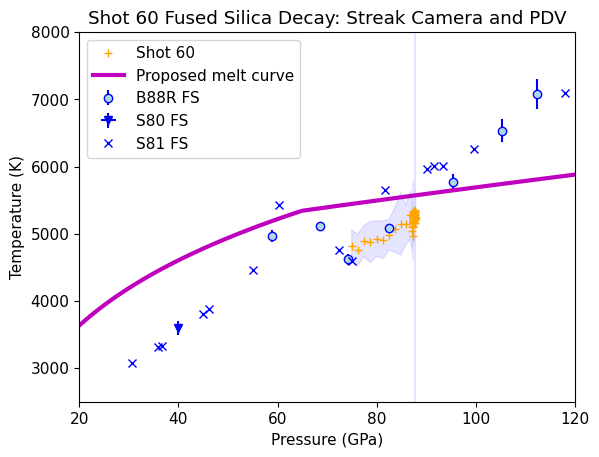

In [10]:

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Shot 60 Fused Silica Decay: Streak Camera and PDV')
plt.plot(s60pres[ind60],s60temp[ind60],'+',color='orange',label='Shot 60')
plt.fill_between(s60pres[ind60[isort]],s60temp[ind60[isort]]-s60temperr[ind60[isort]],s60temp[ind60[isort]]+s60temperr[ind60[isort]], color='blue', alpha = 0.1)

if 1:
    #plt.errorbar(shockdat_list[B88fs['id']].P,shockdat_list[B88fs['id']].T,fmt='bo',mfc='white',yerr=shockdat_list[B88fs['id']].T_std,label=B88fs['lab'])
    ind = np.where(shockdat_list[B88RRfs['id']].T>0)
    plt.errorbar(shockdat_list[B88RRfs['id']].P[ind],shockdat_list[B88RRfs['id']].T[ind],fmt='bo',mfc='lightblue',yerr=shockdat_list[B88RRfs['id']].T_std[ind],label=B88RRfs['lab'])

    plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
    plt.errorbar(shockdat_list[S81fs['id']].P,shockdat_list[S81fs['id']].T,fmt='bx',label=S81fs['lab'])
    plt.xlim(20,120)
    plt.ylim(2500,8000)

    plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Proposed melt curve')
plt.legend()
plt.savefig('shot60/shot60-comp-data.png')
plt.show()

## Compare to Omega Fused Silica decaying shock


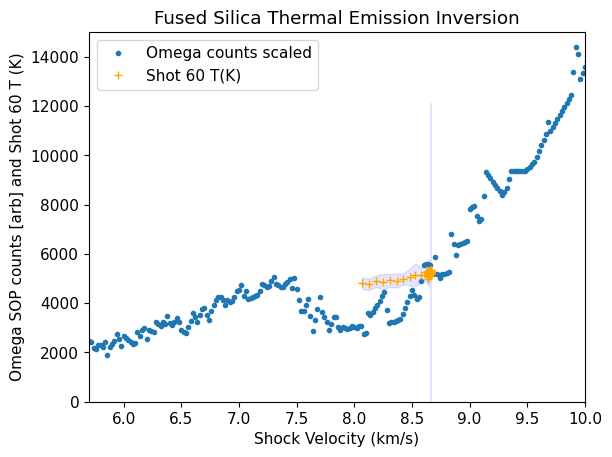

Transition pressures:  65.75888432048565 73.53633751077847


In [11]:
#plt.plot(omegafsus,omegafsct*30,'.',label='Omega counts scaled')
plt.plot(shockdat[iMDfs69691.i].us,shockdat[iMDfs69691.i].T*20,'.',label='Omega counts scaled')

# set in define_eos.py
#fs_usmin = 7.4
#fs_usmax = 8.3
#plt.plot([fs_usmin,fs_usmin],[0,20000],'k-')
#plt.plot([7.75,7.75],[0,1000])
#plt.plot([fs_usmax,fs_usmax],[0,20000],'k-')
plt.ylim(0,15000)
plt.xlim(5.7,10)

plt.plot(s60us[ind60]/1.e3,s60temp[ind60],'+',color='orange',label='Shot 60 T(K)')
plt.fill_between(s60us[ind60[isort]]/1.e3,s60temp[ind60[isort]]-s60temperr[ind60[isort]],s60temp[ind60[isort]]+s60temperr[ind60[isort]], color='blue', alpha = 0.1)

#i60 = np.where(s60temp>0)[0]
#plt.plot(s60us[i60]/1.e3,s60temp[i60],label='Shot 60')
#plt.fill_between(s60us[i60]/1.e3,s60temp[i60]-s60temperr[i60],s60temp[i60]+s60temperr[i60], color='blue', alpha = 0.1)

plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Omega SOP counts [arb] and Shot 60 T (K)')
plt.title('Fused Silica Thermal Emission Inversion')
plt.legend()
plt.savefig('shot60/omega-shot60.png')
plt.show()
#fs_wiggle_P1 = np.interp(fs_usmax,fs_hug_liq.us,fs_hug_liq.P)

print('Transition pressures: ',fs_wiggle_P1, fs_wiggle_P2)

## PDV release velocity

No index correction for free surface particle velocity.

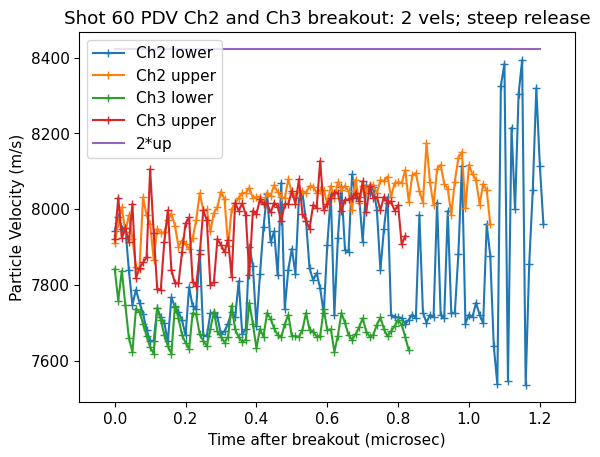

In [12]:
# offset 3769 m/s
# n = 1.444
pdv2datab = np.loadtxt('shot60/Shot60-PDV-ch2-breakout-lower.txt',skiprows=30)
pdv2datab[:,0]-=pdv2datab[0,0]
pdv2datab[:,0]*=1.e6
pdv2datab[:,1]+=3769

pdv2datac = np.loadtxt('shot60/Shot60-PDV-ch2-breakout-upper.txt',skiprows=30)
pdv2datac[:,0]-=pdv2datac[0,0]
pdv2datac[:,0]*=1.e6
pdv2datac[:,1]+=3769

# offset 4495 m/s
# n = 1.444
pdv3datab = np.loadtxt('shot60/Shot60-PDV-ch3-breakout-lower.txt',skiprows=30)
pdv3datab[:,0]-=pdv3datab[0,0]
pdv3datab[:,0]*=1.e6
pdv3datab[:,1]+=4495

pdv3datac = np.loadtxt('shot60/Shot60-PDV-ch3-breakout-upper.txt',skiprows=30)
pdv3datac[:,0]-=pdv3datac[0,0]
pdv3datac[:,0]*=1.e6
pdv3datac[:,1]+=4495

plt.plot(pdv2datab[:,0],pdv2datab[:,1],'-+',label='Ch2 lower')
plt.plot(pdv2datac[:,0],pdv2datac[:,1],'-+',label='Ch2 upper')
plt.plot(pdv3datab[:,0],pdv3datab[:,1],'-+',label='Ch3 lower')
plt.plot(pdv3datac[:,0],pdv3datac[:,1],'-+',label='Ch3 upper')

plt.plot([0,1.2],[lastup2*2*1.e3,lastup2*2*1.e3],label='2*up')
plt.xlim(-.1,1.3)
plt.legend(loc='upper left')


plt.title('Shot 60 PDV Ch2 and Ch3 breakout: 2 vels; steep release')
plt.xlabel('Time after breakout (microsec)')
plt.ylabel('Particle Velocity (m/s)')
plt.savefig('shot60/shot60-release-vel.png')

The PDV shows two velocity signals, indicating spalling and a solid surface.<p>

Steeper release than velocity doubling also implies not a fluid at free surface.


## Save the calibrated time series of data for plotting elsewhere.

In [13]:
import pickle
s60Tsteady=Tsteady
s60Tsteady_err=Tsteady_err
s60Psteady=Psteady
s60Psteady_err=Psteady_err
s60Ussteady = Ussteady
s60Ussteady_err = Ussteady_err

# obj0, obj1, obj2 are created here...
isort60=isort
# Saving the objects:
with open('shot60/shot60-analysis.pkl', 'wb') as f:  # Python 3: open(..., 'wb')
    pickle.dump([s60time, s60temp, s60temperr, s60pres, s60us, s60us_err, s60up, ind60, isort60, s60Tsteady,s60Tsteady_err,s60Psteady,s60Psteady_err,s60Ussteady,s60Ussteady_err], f)

#print(s60time)
#    with open('shot60/objs-tra.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
#    s60time, s60temp, s60temperr, s60pres, s60us, s60us_err, s60up, ind60, isort60,s60Tsteady,s60Tsteady_err,s60Psteady,s60Psteady_err,s60Ussteady,s60Ussteady_err=pickle.load(f)

# Getting back the objects:
#with open('objs.pkl') as f:  # Python 3: open(..., 'rb')
#    obj0, obj1, obj2 = pickle.load(f)

In [14]:
## end of notebook